# Question 8: how much of the rise in the mortgage share came from prices, rates and income?

The mortgage share (Q6) is price × financing cost per dollar ÷ income, where financing is principal and interest per
dollar of home value (10% down, 30-year fixed at that month's Freddie Mac rate) plus property tax per dollar
(`property_tax_rate`). In logs the three add up exactly, so the change in the log share splits into a price part
(Zillow ZHVI), a financing part and an income part (ACS 1-year, a rise counts against the share). Each period is the
mean of its monthly logs: 2015, 2021 and the latest 12 months. Source: `gold.mart_metro_month`; helper
`mortgage_share_split()` in `common.py`.

Caveats: log points are not percentage points of income; 0.10 means the share is about 10% higher. The financing part
mixes rates and tax rates; tax rates fell a little in most metros, so the rate effect alone is slightly larger.
Lagged ACS income (carried forward after 2025) makes the latest income part a little too small.

In [1]:
import common as c

In [2]:
d = c.mortgage_share_split()
d.round(3)

price  financing  income  total
window      metro                                             
2015-2021   Atlanta            0.533     -0.114  -0.277  0.142
            Austin             0.520     -0.135  -0.269  0.116
            Charlotte          0.545     -0.142  -0.256  0.148
            Dallas-Fort Worth  0.513     -0.127  -0.233  0.152
            Denver             0.503     -0.113  -0.285  0.105
            Nashville          0.545     -0.139  -0.255  0.151
            Orlando            0.501     -0.132  -0.276  0.093
            Phoenix            0.596     -0.137  -0.331  0.127
            Raleigh            0.435     -0.127  -0.259  0.049
            Seattle            0.604     -0.125  -0.304  0.175
            Tampa              0.579     -0.127  -0.277  0.175
2015-latest Atlanta            0.743      0.236  -0.428  0.551
            Austin             0.470      0.177  -0.396  0.251
            Charlotte          0.783      0.212  -0.443  0.552
            Dallas-Fort Worth  0.665      0.153  -0.413  0.405
            Denver             0.590      0.261  -0.416  0.434
            Nashville          0.766      0.219  -0.446  0.539
            Orlando            0.728      0.223  -0.500  0.451
            Phoenix            0.725      0.226  -0.474  0.477
            Raleigh            0.645      0.229  -0.396  0.479
            Seattle            0.749      0.222  -0.446  0.525
            Tampa              0.780      0.227  -0.504  0.503
2021-latest Atlanta            0.210      0.350  -0.151  0.410
            Austin            -0.050      0.312  -0.127  0.135
            Charlotte          0.238      0.354  -0.188  0.404
            Dallas-Fort Worth  0.152      0.281  -0.180  0.253
            Denver             0.086      0.374  -0.131  0.329
            Nashville          0.221      0.359  -0.191  0.388
            Orlando            0.227      0.355  -0.224  0.358
            Phoenix            0.129      0.363  -0.143  0.350
            Raleigh            0.210      0.357  -0.137  0.430
            Seattle            0.145      0.347  -0.142  0.349
            Tampa              0.202      0.354  -0.228  0.328

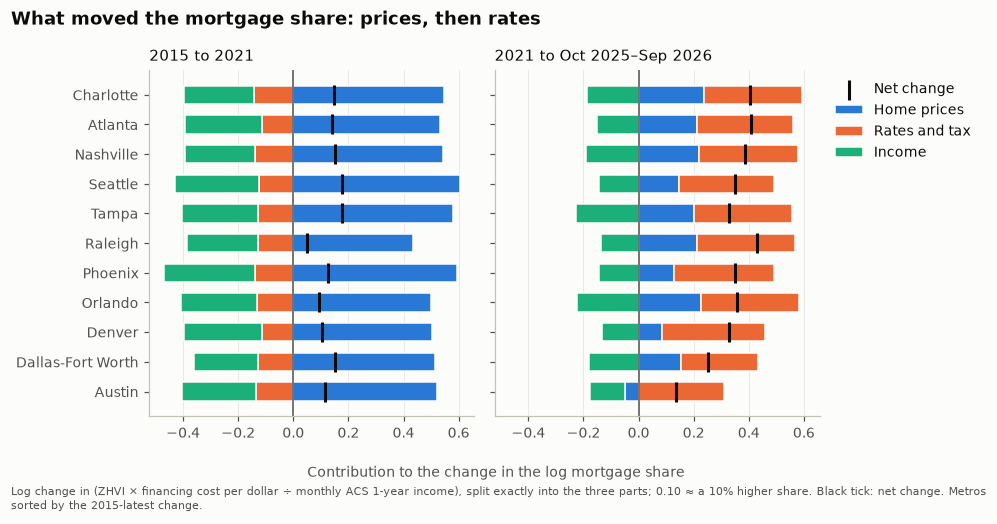

In [3]:
parts = {
    "price": ("Home prices", c.BLUE),
    "financing": ("Rates and tax", c.ORANGE),
    "income": ("Income", c.AQUA),
}
windows = ["2015-2021", "2021-latest"]
order = d.loc["2015-latest"].total.sort_values().index
fig, axes = c.plt.subplots(1, 2, figsize=(9, 4.4), sharey=True, sharex=True)
for ax, w in zip(axes, windows):
    x = d.loc[w].reindex(order)
    pos, neg = c.np.zeros(len(x)), c.np.zeros(len(x))
    for col, (label, color) in parts.items():
        v = x[col].to_numpy()
        base = c.np.where(v >= 0, pos, neg)
        ax.barh(
            order,
            v,
            left=base,
            color=color,
            height=0.62,
            edgecolor=c.SURFACE,
            linewidth=1,
            label=label,
        )
        pos, neg = pos + c.np.maximum(v, 0), neg + c.np.minimum(v, 0)
    ax.scatter(
        x.total,
        range(len(x)),
        marker="|",
        s=160,
        color=c.INK,
        zorder=4,
        label="Net change",
    )
    ax.axvline(0, color=c.INK2, lw=1)
    ax.grid(axis="y", visible=False)
    ax.set_title("2015 to 2021" if w == "2015-2021" else f"2021 to {c.LATEST_12M}")
fig.supxlabel(
    "Contribution to the change in the log mortgage share", fontsize=9, color=c.INK2
)
axes[1].legend(loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
c.save(
    fig,
    "q8_mortgage_share_split",
    "What moved the mortgage share: prices, then rates",
    "Log change in (ZHVI × financing cost per dollar ÷ monthly ACS 1-year income), split exactly into the three parts; "
    "0.10 ≈ a 10% higher share. Black tick: net change. Metros sorted by the 2015-latest change.",
)

## Answer

In [4]:
for w in ["2015-2021", "2021-latest", "2015-latest"]:
    x = d.loc[w]
    print(
        f"{w}: median net {x.total.median():+.2f} log points = price {x.price.median():+.2f}, "
        f"financing {x.financing.median():+.2f}, income {x.income.median():+.2f}; "
        f"price outweighs financing in {(x.price >= x.financing).sum()} of {len(x)} metros"
    )
s = d.loc["2015-latest"].loc["Seattle"]
print(
    f"Seattle 2015-latest: net {s.total:+.2f} = price {s.price:+.2f}, financing {s.financing:+.2f}, income {s.income:+.2f}"
)

2015-2021: median net +0.14 log points = price +0.53, financing -0.13, income -0.28; price outweighs financing in 11 of 11 metros
2021-latest: median net +0.35 log points = price +0.20, financing +0.35, income -0.15; price outweighs financing in 0 of 11 metros
2015-latest: median net +0.48 log points = price +0.73, financing +0.22, income -0.44; price outweighs financing in 11 of 11 metros
Seattle 2015-latest: net +0.52 = price +0.75, financing +0.22, income -0.45
